In [1]:

import numpy as np
import matplotlib.pyplot as plt
import torch
import tensorflow as tf
from itertools import product

torch.manual_seed(0)
tf.random.set_seed(0)
np.set_printoptions(precision=4, suppress=True)
print(f"PyTorch {torch.__version__} | TensorFlow {tf.__version__}")

PyTorch 2.15.0 | TensorFlow 2.22.0-rc0


### Activation functions: input range and derivatives

#### From a biological neuron to an artificial one

| Biological neuron | Artificial neuron |
|---|---|
| **Dendrites** receive signals from other neurons | **Inputs** $x_1, \dots, x_m$ |
| **Synapses** make some connections stronger than others | **Weights** $w_1, \dots, w_m$ (a negative weight is an *inhibitory* synapse) |
| The **cell body (soma)** adds up all incoming signals | **Weighted sum** $\sum_j w_j x_j$ |
| The neuron's **firing threshold** | **Bias** $b$ (equivalently $w_0$ with a constant input $x_0 = 1$) |
| The neuron **fires** an impulse down the **axon** only if the summed signal passes the threshold | The **activation function** $A(z)$ turns the sum into an output $\hat{y}$ |

So every neuron in this notebook does two steps:

$$
z = \sum_{j=1}^{m} w_j x_j + b \qquad\qquad \hat{y} = A(z)
$$

* **Weighted inputs:** a large positive $w_j$ means input $j$ pushes strongly towards firing, a negative $w_j$ pushes against it, and $w_j = 0$ means the input is ignored.
* **Bias:** shifts the threshold. With $b = -1.5$, the weighted inputs must add up to more than 1.5 before $z > 0$. Raising the bias makes the neuron easier to fire, and lowering it makes the neuron harder to fire.

#### The five activation functions and their derivatives

Derivatives matter because gradient descent (last section) multiplies by $A'(z)$ when it updates the weights. If $A'(z) \approx 0$, the weights barely change.

| Function | Formula $A(z)$ | Derivative $A'(z)$ | Output range |
|---|---|---|---|
| Identity | $z$ | $1$ | $(-\infty, \infty)$ |
| Binary step | $\begin{cases}1 & z > 0\\ 0 & z \le 0\end{cases}$ | $0$ for $z \neq 0$, undefined at $0$ | $\{0, 1\}$ |
| Sigmoid | $\sigma(z) = \dfrac{1}{1 + e^{-z}}$ | $\sigma(z)\,\big(1 - \sigma(z)\big)$, max $0.25$ at $z=0$ | $(0, 1)$ |
| Tanh | $\dfrac{e^{z} - e^{-z}}{e^{z} + e^{-z}}$ | $1 - \tanh^2(z)$, max $1$ at $z=0$ | $(-1, 1)$ |
| ReLU | $\max(0, z)$ | $1$ for $z > 0$, $0$ for $z < 0$ (we use $0$ at $z=0$, as PyTorch and TensorFlow do) | $[0, \infty)$ |

**Derivation of the sigmoid derivative**, used again in the gradient descent section:

$$
\sigma'(z) = \frac{d}{dz}\,(1 + e^{-z})^{-1} = \frac{e^{-z}}{(1 + e^{-z})^2}
= \underbrace{\frac{1}{1 + e^{-z}}}_{\sigma(z)} \cdot \underbrace{\frac{e^{-z}}{1 + e^{-z}}}_{1 - \sigma(z)}
$$

**Note on the step function:** the workshop's perceptrons use $z > 0$ (strict), so $z = 0$ gives output 0. We use the same rule throughout.

The cell below plots each function on a **narrow range $[-3, 3]$** and a **wide range $[-50, 50]$**, plots the derivatives, and then checks our hand-written derivatives against **PyTorch autograd** and **TensorFlow `GradientTape`**.

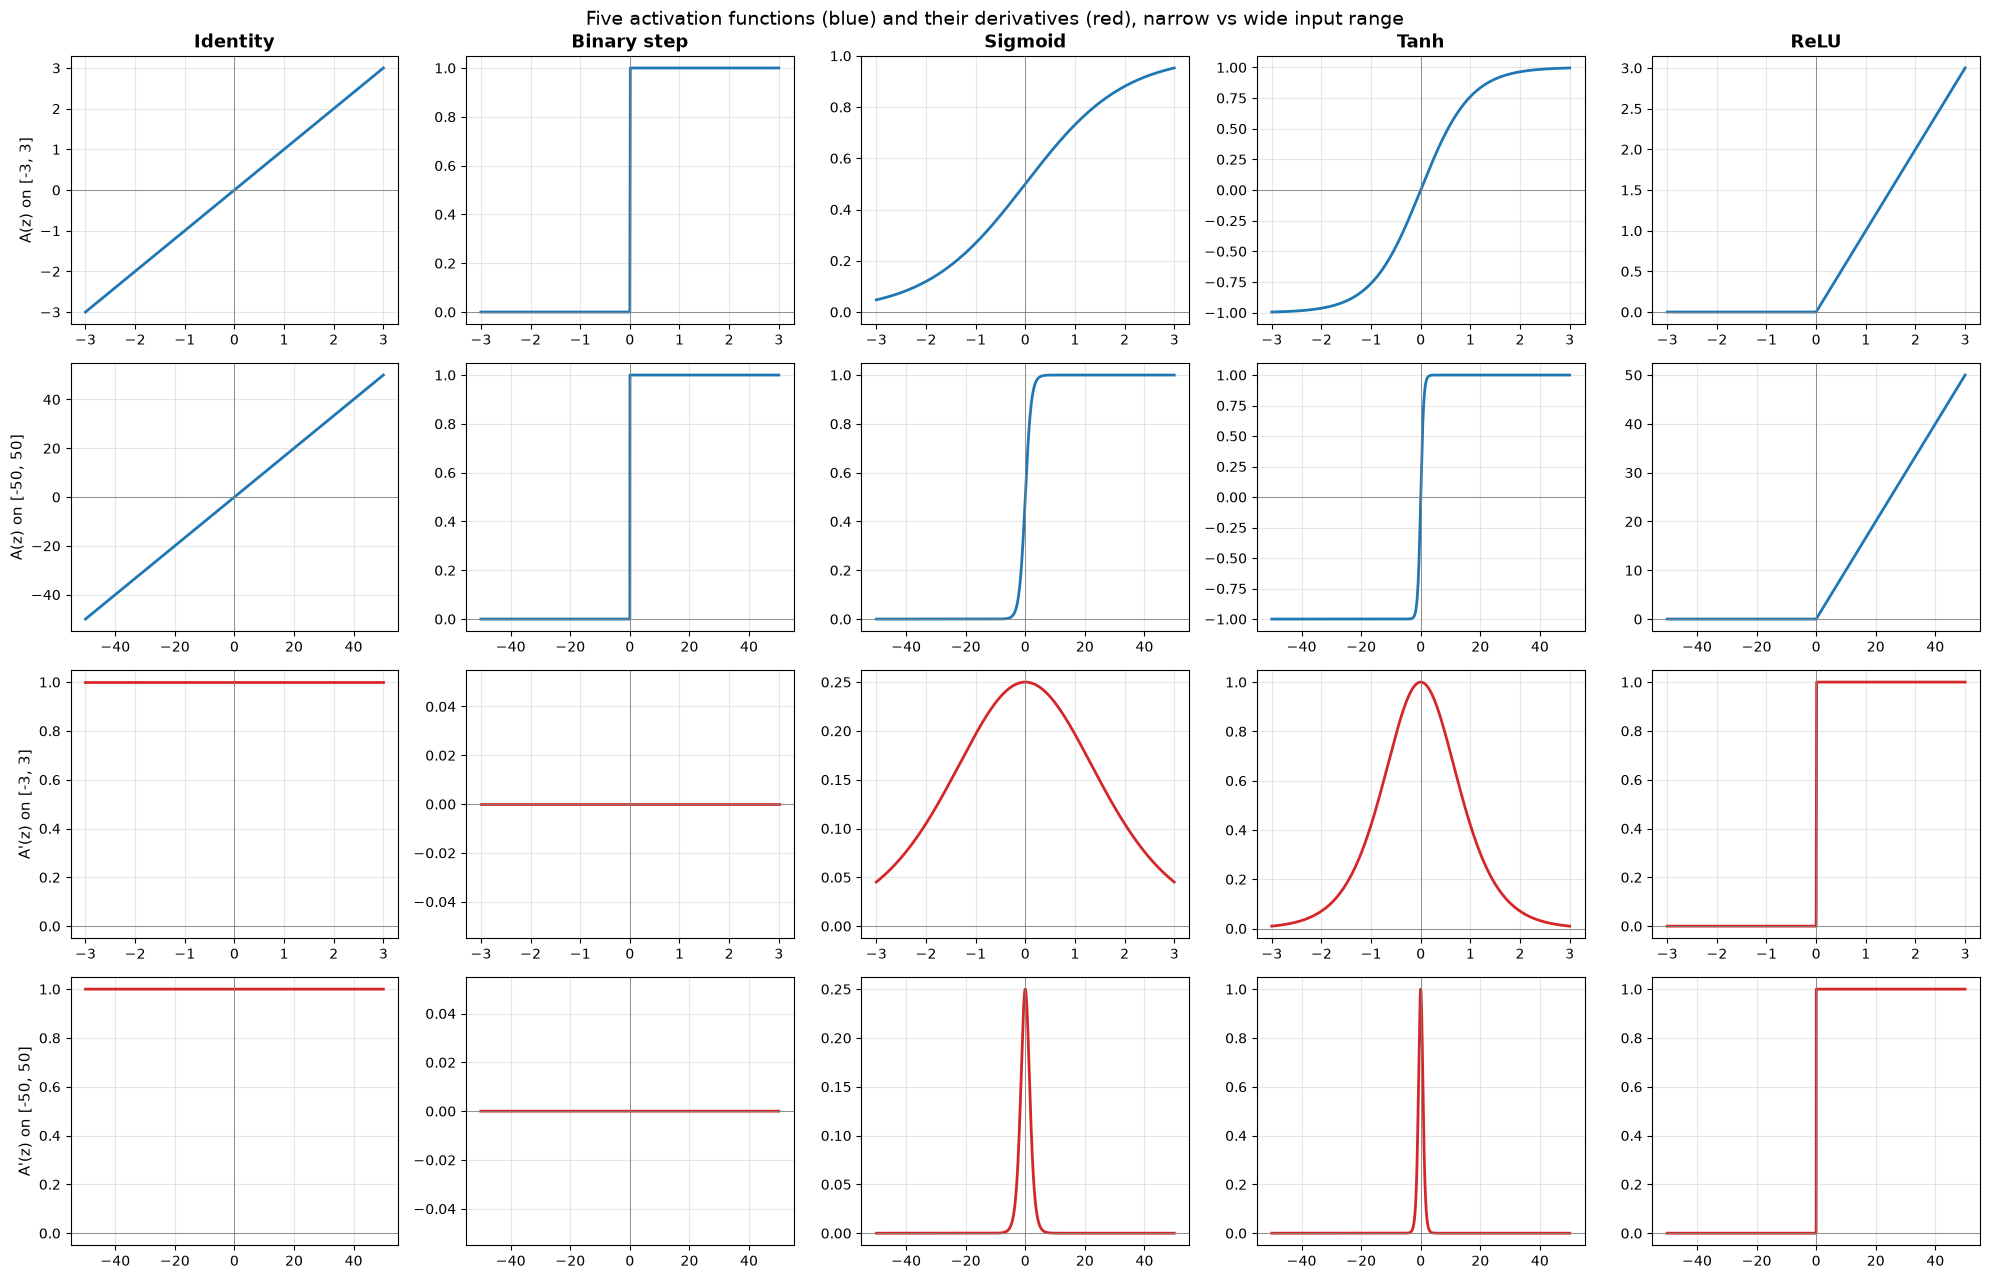

In [2]:
# --- Activation functions and their derivatives (NumPy, so we can plot them) ---
def identity(z):     return z
def d_identity(z):   return np.ones_like(z)

def step(z):         return np.where(z > 0, 1.0, 0.0)          # same z > 0 rule as the workshop
def d_step(z):       return np.zeros_like(z)                    # flat everywhere (undefined at 0)

def sigmoid(z):      return 1.0 / (1.0 + np.exp(-z))
def d_sigmoid(z):    s = sigmoid(z); return s * (1.0 - s)

def tanh(z):         return np.tanh(z)
def d_tanh(z):       return 1.0 - np.tanh(z) ** 2

def relu(z):         return np.maximum(0.0, z)
def d_relu(z):       return np.where(z > 0, 1.0, 0.0)

activations = {
    "Identity":    (identity, d_identity),
    "Binary step": (step,     d_step),
    "Sigmoid":     (sigmoid,  d_sigmoid),
    "Tanh":        (tanh,     d_tanh),
    "ReLU":        (relu,     d_relu),
}

z_narrow = np.linspace(-3, 3, 601)
z_wide   = np.linspace(-50, 50, 2001)

fig, axes = plt.subplots(4, 5, figsize=(20, 13), sharex="row")
rows = [("A(z) on [-3, 3]",   z_narrow, 0, "tab:blue"),
        ("A(z) on [-50, 50]", z_wide,   0, "tab:blue"),
        ("A'(z) on [-3, 3]",  z_narrow, 1, "tab:red"),
        ("A'(z) on [-50, 50]", z_wide,  1, "tab:red")]

for r, (label, z, which, colour) in enumerate(rows):
    for c, (name, fns) in enumerate(activations.items()):
        ax = axes[r, c]
        ax.plot(z, fns[which](z), color=colour, lw=2)
        ax.axhline(0, color="grey", lw=0.6); ax.axvline(0, color="grey", lw=0.6)
        ax.grid(alpha=0.3)
        if r == 0: ax.set_title(name, fontsize=13, fontweight="bold")
        if c == 0: ax.set_ylabel(label, fontsize=11)

fig.suptitle("Five activation functions (blue) and their derivatives (red), narrow vs wide input range",
             fontsize=14)
plt.tight_layout()
plt.show()

In [3]:
# --- Check the hand-written derivatives against both frameworks' automatic differentiation ---
z_np = z_narrow.astype(np.float32)

torch_fns = {"Identity": lambda t: t, "Sigmoid": torch.sigmoid, "Tanh": torch.tanh, "ReLU": torch.relu}
tf_fns    = {"Identity": tf.identity, "Sigmoid": tf.math.sigmoid, "Tanh": tf.math.tanh, "ReLU": tf.nn.relu}

print(f"{'Function':<10} | {'max |numpy - torch|':>20} | {'max |numpy - tf|':>17}")
print("-" * 54)
for name in torch_fns:
    # PyTorch: summing the outputs and calling backward() gives dA/dz at every point
    z_t = torch.tensor(z_np, requires_grad=True)
    torch_fns[name](z_t).sum().backward()
    grad_torch = z_t.grad.numpy()

    # TensorFlow: GradientTape records the forward pass, then tape.gradient differentiates it
    z_tf = tf.constant(z_np)
    with tf.GradientTape() as tape:
        tape.watch(z_tf)
        out = tf_fns[name](z_tf)
    grad_tf = tape.gradient(out, z_tf).numpy()

    ours = activations[name][1](z_np)
    err_t, err_tf = np.max(np.abs(ours - grad_torch)), np.max(np.abs(ours - grad_tf))
    assert err_t < 1e-5 and err_tf < 1e-5, f"{name}: derivative mismatch"
    print(f"{name:<10} | {err_t:>20.2e} | {err_tf:>17.2e}")

print("\nAll analytic derivatives match PyTorch autograd and TensorFlow GradientTape.")
print("(The binary step has no useful gradient, which is why it can't be trained with gradient descent.)")

# Size of the sigmoid and tanh gradients far from zero
for zv in [0, 3, 10, 50]:
    print(f"z = {zv:>2}:  sigmoid'(z) = {d_sigmoid(np.float64(zv)):.2e}   tanh'(z) = {d_tanh(np.float64(zv)):.2e}")

Function   |  max |numpy - torch| |  max |numpy - tf|
------------------------------------------------------
Identity   |             0.00e+00 |          0.00e+00
Sigmoid    |             5.22e-08 |          1.04e-07
Tanh       |             1.19e-07 |          2.38e-07
ReLU       |             0.00e+00 |          0.00e+00

All analytic derivatives match PyTorch autograd and TensorFlow GradientTape.
(The binary step has no useful gradient, which is why it can't be trained with gradient descent.)
z =  0:  sigmoid'(z) = 2.50e-01   tanh'(z) = 1.00e+00
z =  3:  sigmoid'(z) = 4.52e-02   tanh'(z) = 9.87e-03
z = 10:  sigmoid'(z) = 4.54e-05   tanh'(z) = 8.24e-09
z = 50:  sigmoid'(z) = 0.00e+00   tanh'(z) = 0.00e+00


#### What the two input ranges show

* **On $[-3, 3]$**, sigmoid and tanh look like smooth S-curves and their derivatives are clearly non-zero. In this region a small change in $z$ still changes the output, so the neuron can learn.
* **On $[-50, 50]$**, sigmoid and tanh look almost exactly like the **binary step**: they **saturate** at 0/1 (or −1/1) once $|z|$ is more than about 5. Their derivatives drop to almost nothing. The check above shows $\sigma'(10) \approx 4.5 \times 10^{-5}$, and at $z = 50$ the derivative is effectively zero. This is the **vanishing gradient** problem: a saturated neuron passes back almost no gradient, so its weights stop updating.
* **ReLU** never saturates for positive $z$ (its derivative stays 1), which is why it is the default for hidden layers. Its weakness is the flat zero region. A neuron whose $z$ is always negative gets zero gradient and stops learning (a "dead ReLU").
* **Identity** has a constant derivative of 1 but adds no non-linearity, so stacking identity layers is still just one linear layer.
* **Binary step** has a derivative of 0 everywhere it is defined. It works for hand-built logic gates (next section), but you cannot train it with gradient descent, which is why trained networks use sigmoid, tanh or ReLU instead.

### Verifying logic gates in both frameworks

A single-layer perceptron with a **step activation** can act as a logic gate. Below, `verify_gate(weights, bias, expected)`:

1. builds **every binary input combination** for the number of inputs (2 inputs → 4 rows, 3 inputs → 8 rows), in `itertools.product` order: `(0,0), (0,1), (1,0), (1,1)`;
2. computes the weighted sum $z = \mathbf{X}\mathbf{w} + b$ in **PyTorch** and, separately, in **TensorFlow**;
3. applies the step function ($1$ if $z > 0$, else $0$);
4. uses **`assert`** to check that both frameworks give the expected truth table and the same $z$ values;
5. prints the truth table and returns the $z$ values, which we use to explain inhibition.

If any row is wrong, the notebook stops with an `AssertionError` that names the row, so a mistake can't go unnoticed.

In [4]:
def verify_gate(weights, bias, expected, name="gate", input_names=None):
    """Check a step-activation perceptron against its expected truth table in PyTorch AND TensorFlow.

    weights  : list of floats, one per input
    bias     : float
    expected : list of 0/1 outputs, one per row of product([0, 1], repeat=len(weights))
    Returns the z values (NumPy array) so they can be inspected or plotted.
    """
    n = len(weights)
    combos = list(product([0, 1], repeat=n))
    assert len(expected) == len(combos), f"{name}: need {len(combos)} expected outputs, got {len(expected)}"
    X = np.array(combos, dtype=np.float32)
    input_names = input_names or [chr(ord("A") + i) for i in range(n)]

    # --- PyTorch: weighted sum, then step activation ---
    w_torch = torch.tensor(weights, dtype=torch.float32)
    z_torch = torch.matmul(torch.from_numpy(X), w_torch) + bias
    out_torch = (z_torch > 0).int().tolist()

    # --- TensorFlow: same computation ---
    w_tf = tf.constant(weights, dtype=tf.float32)
    z_tf = tf.linalg.matvec(tf.constant(X), w_tf) + bias
    out_tf = tf.cast(z_tf > 0, tf.int32).numpy().tolist()

    # --- Print the truth table ---
    header = " ".join(f"{s:>2}" for s in input_names)
    print(f"{name}   (weights={weights}, bias={bias})")
    print(f"{header} | {'z (torch)':>9} | {'z (tf)':>7} | out torch | out tf | expected")
    print("-" * (len(header) + 56))
    for row, zt, ztf, ot, otf, e in zip(combos, z_torch.tolist(), z_tf.numpy(), out_torch, out_tf, expected):
        flag = "" if ot == otf == e else "   <-- MISMATCH"
        print(f"{' '.join(f'{v:>2}' for v in row)} | {zt:>9.1f} | {ztf:>7.1f} | {ot:>9} | {otf:>6} | {e:>8}{flag}")

    # --- The checks ---
    assert np.allclose(z_torch.numpy(), z_tf.numpy()), f"{name}: PyTorch and TensorFlow disagree on z"
    for row, ot, otf, e in zip(combos, out_torch, out_tf, expected):
        assert ot == e,  f"{name}: PyTorch gives {ot} for input {row}, expected {e}"
        assert otf == e, f"{name}: TensorFlow gives {otf} for input {row}, expected {e}"
    print(f"✅ {name} passes in PyTorch and TensorFlow\n")
    return z_torch.numpy()

In [5]:
# Weights and biases are the ones from the workshop slides.
# Expected outputs follow product([0, 1], repeat=n) order: (0,0), (0,1), (1,0), (1,1).

z_identity = verify_gate([2.0], -1.0, [0, 1],                  name="Case 1: C = A")
z_and      = verify_gate([1.0, 1.0], -1.5, [0, 0, 0, 1],       name="Case 2: C = A AND B")
z_or       = verify_gate([1.0, 2.0], -0.5, [0, 1, 1, 1],       name="Case 3: C = A OR B")
z_inhibit  = verify_gate([1.0, -1.0], -0.5, [0, 0, 1, 0],      name="Case 4: C = A AND NOT B")

Case 1: C = A   (weights=[2.0], bias=-1.0)
 A | z (torch) |  z (tf) | out torch | out tf | expected
----------------------------------------------------------
 0 |      -1.0 |    -1.0 |         0 |      0 |        0
 1 |       1.0 |     1.0 |         1 |      1 |        1
✅ Case 1: C = A passes in PyTorch and TensorFlow

Case 2: C = A AND B   (weights=[1.0, 1.0], bias=-1.5)
 A  B | z (torch) |  z (tf) | out torch | out tf | expected
-------------------------------------------------------------
 0  0 |      -1.5 |    -1.5 |         0 |      0 |        0
 0  1 |      -0.5 |    -0.5 |         0 |      0 |        0
 1  0 |      -0.5 |    -0.5 |         0 |      0 |        0
 1  1 |       0.5 |     0.5 |         1 |      1 |        1
✅ Case 2: C = A AND B passes in PyTorch and TensorFlow

Case 3: C = A OR B   (weights=[1.0, 2.0], bias=-0.5)
 A  B | z (torch) |  z (tf) | out torch | out tf | expected
-------------------------------------------------------------
 0  0 |      -0.5 |    -0.5 | 

In [6]:
# Showing that the asserts work: give OR the AND gate's truth table on purpose.
try:
    verify_gate([1.0, 2.0], -0.5, [0, 0, 0, 1], name="OR weights checked against the AND table (deliberately wrong)")
except AssertionError as err:
    print(f"\n❌ AssertionError caught as intended: {err}")

OR weights checked against the AND table (deliberately wrong)   (weights=[1.0, 2.0], bias=-0.5)
 A  B | z (torch) |  z (tf) | out torch | out tf | expected
-------------------------------------------------------------
 0  0 |      -0.5 |    -0.5 |         0 |      0 |        0
 0  1 |       1.5 |     1.5 |         1 |      1 |        0   <-- MISMATCH
 1  0 |       0.5 |     0.5 |         1 |      1 |        0   <-- MISMATCH
 1  1 |       2.5 |     2.5 |         1 |      1 |        1

❌ AssertionError caught as intended: OR weights checked against the AND table (deliberately wrong): PyTorch gives 1 for input (0, 1), expected 0


**How each gate works** (read the $z$ column above):

* **C = A** ($w = 2, b = -1$): $A = 0 \Rightarrow z = -1$ (off); $A = 1 \Rightarrow z = 1$ (on). The output copies the input.
* **AND** ($w = [1, 1], b = -1.5$): one active input gives $z = -0.5$, which is not enough. Only both together reach $z = 0.5 > 0$. The bias sets the bar above what one input can reach alone.
* **OR** ($w = [1, 2], b = -0.5$): one active input is enough: $A$ alone gives $z = 0.5$, $B$ alone gives $z = 1.5$. The larger weight on $B$ means $B$ has more influence, but either input can fire the neuron.
* **A ∧ ¬B** ($w = [1, -1], b = -0.5$): explained in the next section.

In both frameworks the calculation is the same: a **dot product** (`torch.matmul` / `tf.linalg.matvec`), **plus the bias**, then a **threshold**. The two libraries only differ in syntax.

### How a negative weight inhibits activation

For **C = A ∧ ¬B** the weights are $w_A = +1$ (**excitatory**) and $w_B = -1$ (**inhibitory**), with $b = -0.5$:

$$
z = (+1)\,A + (-1)\,B - 0.5
$$

| A | B | Calculation | $z$ | C = step(z) | What happens |
|---|---|---|---|---|---|
| 0 | 0 | $0 - 0 - 0.5$ | $-0.5$ | 0 | Only the bias acts, so the neuron stays off |
| 0 | 1 | $0 - 1 - 0.5$ | $-1.5$ | 0 | B pushes $z$ further below zero |
| **1** | **0** | $1 - 0 - 0.5$ | **$+0.5$** | **1** | A alone gets over the threshold, so the neuron fires |
| 1 | 1 | $1 - 1 - 0.5$ | $-0.5$ | 0 | **B cancels A exactly**, pulling $z$ back to the "off" level |

Compare the rows where A = 1: switching B on drops $z$ from **+0.5 to −0.5**, a change of exactly $w_B = -1$. A negative weight **subtracts** from the evidence for firing, just as an inhibitory synapse in the brain lowers a neuron's membrane potential. Because $|w_B| = |w_A|$, B always cancels A completely, so **no combination with B = 1 can fire the neuron**. B works as a veto.

The bias matters too: with $b = -0.5$, A's +1 is only just enough to cross zero. If the bias were $+0.5$, the row A = 1, B = 1 would give $z = +0.5$ and the neuron would fire even with B on, so the inhibition would fail.

In [7]:
#  The correct weighted sum uses each input with its own weight: z = w[0]*A + w[1]*B + bias.

weights = [1.0, -1.0]   # A excites (+1), B inhibits (-1)
bias = -0.5
inputs = [(0, 0), (1, 0), (0, 1), (1, 1)]

def step_scalar(x):
    return 1 if x > 0 else 0

print("🔵 PyTorch")
for A, B in inputs:
    x = torch.tensor([A, B], dtype=torch.float32)
    w = torch.tensor(weights)
    z = torch.dot(w, x) + bias          # z = w[0]*A + w[1]*B + bias   (corrected comment)
    print(f"A={A}, B={B} → z={z.item():+.1f} → C={step_scalar(z.item())}")

print("\n🟢 TensorFlow")
for A, B in inputs:
    x = tf.constant([A, B], dtype=tf.float32)
    w = tf.constant(weights)
    z = tf.reduce_sum(w * x) + bias     # z = w[0]*A + w[1]*B + bias
    print(f"A={A}, B={B} → z={z.numpy():+.1f} → C={step_scalar(z.numpy())}")

🔵 PyTorch
A=0, B=0 → z=-0.5 → C=0
A=1, B=0 → z=+0.5 → C=1
A=0, B=1 → z=-1.5 → C=0
A=1, B=1 → z=-0.5 → C=0

🟢 TensorFlow
A=0, B=0 → z=-0.5 → C=0
A=1, B=0 → z=+0.5 → C=1
A=0, B=1 → z=-1.5 → C=0
A=1, B=1 → z=-0.5 → C=0


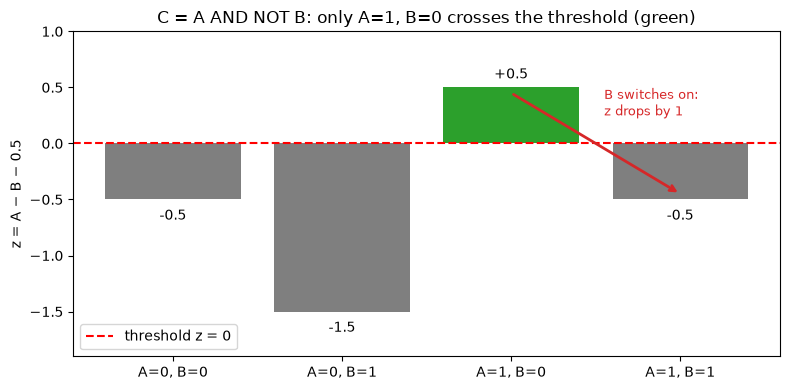

In [8]:
# Visualising inhibition: z for every input row, with the firing threshold at z = 0
labels = ["A=0, B=0", "A=0, B=1", "A=1, B=0", "A=1, B=1"]      # product() order, same as z_inhibit
colours = ["tab:green" if z > 0 else "tab:grey" for z in z_inhibit]

fig, ax = plt.subplots(figsize=(8, 4))
bars = ax.bar(labels, z_inhibit, color=colours)
ax.axhline(0, color="red", ls="--", lw=1.5, label="threshold z = 0")
for bar, z in zip(bars, z_inhibit):
    ax.text(bar.get_x() + bar.get_width() / 2, z + (0.08 if z > 0 else -0.18), f"{z:+.1f}", ha="center")
ax.annotate("", xy=(3, -0.45), xytext=(2, 0.45),
            arrowprops=dict(arrowstyle="->", color="tab:red", lw=2))
ax.text(2.55, 0.25, "B switches on:\nz drops by 1", color="tab:red", fontsize=9)
ax.set_ylabel("z = A − B − 0.5"); ax.set_ylim(-1.9, 1.0)
ax.set_title("C = A AND NOT B: only A=1, B=0 crosses the threshold (green)")
ax.legend(loc="lower left"); plt.tight_layout(); plt.show()

### Movie challenge: our own weights

**Inputs** (1 = yes, 0 = no): $x_1$ = good weather, $x_2$ = have company, $x_3$ = cinema is nearby.

The workshop's version uses equal weights $[1, 1, 1]$ and $b = -2.5$, so **all three** must be yes. That is a plain 3-input AND. Our version weights the inputs **unequally** to model a more realistic decision:

$$
w = [\,3,\; 2,\; 1\,], \qquad b = -3.5, \qquad z = 3x_1 + 2x_2 + 1x_3 - 3.5
$$

* **Weather** has the biggest weight (3) and is required. Without it, the best possible score is $2 + 1 - 3.5 = -0.5$, which is below the threshold.
* Weather **alone** is not enough either: $3 - 3.5 = -0.5$.
* Weather **plus at least one** of company or proximity crosses the threshold: $3 + 1 - 3.5 = +0.5$ and $3 + 2 - 3.5 = +1.5$.

So this single neuron computes $x_1 \land (x_2 \lor x_3)$: *"I'll go if the weather is good **and** I either have company **or** the cinema is close."* We check all **8 input combinations** with `verify_gate` in both frameworks, then also pass $z$ through **sigmoid** to show how confident the neuron is, as in the Wonderland example.

In [9]:
movie_weights = [3.0, 2.0, 1.0]     # weather, company, proximity
movie_bias = -3.5
#                 000 001 010 011 100 101 110 111   (x1 x2 x3)
movie_expected = [0,  0,  0,  0,  0,  1,  1,  1]

z_movie = verify_gate(movie_weights, movie_bias, movie_expected,
                      name="Movie decision: weather AND (company OR proximity)",
                      input_names=["x1", "x2", "x3"])

Movie decision: weather AND (company OR proximity)   (weights=[3.0, 2.0, 1.0], bias=-3.5)
x1 x2 x3 | z (torch) |  z (tf) | out torch | out tf | expected
----------------------------------------------------------------
 0  0  0 |      -3.5 |    -3.5 |         0 |      0 |        0
 0  0  1 |      -2.5 |    -2.5 |         0 |      0 |        0
 0  1  0 |      -1.5 |    -1.5 |         0 |      0 |        0
 0  1  1 |      -0.5 |    -0.5 |         0 |      0 |        0
 1  0  0 |      -0.5 |    -0.5 |         0 |      0 |        0
 1  0  1 |       0.5 |     0.5 |         1 |      1 |        1
 1  1  0 |       1.5 |     1.5 |         1 |      1 |        1
 1  1  1 |       2.5 |     2.5 |         1 |      1 |        1
✅ Movie decision: weather AND (company OR proximity) passes in PyTorch and TensorFlow



In [10]:
# Same 8 rows with a sigmoid output in both frameworks, so we also see how confident the neuron is
X_movie = torch.tensor(list(product([0, 1], repeat=3)), dtype=torch.float32)
conf_torch = torch.sigmoid(X_movie @ torch.tensor(movie_weights) + movie_bias)
conf_tf = tf.math.sigmoid(tf.linalg.matvec(tf.constant(X_movie.numpy()), tf.constant(movie_weights)) + movie_bias)
assert np.allclose(conf_torch.numpy(), conf_tf.numpy(), atol=1e-6)

meaning = {(0,0,0): "stay home", (0,0,1): "close, but it's raining", (0,1,0): "friend, but it's raining",
           (0,1,1): "nearby + friend, still raining", (1,0,0): "nice weather, but alone & far",
           (1,0,1): "nice weather + nearby", (1,1,0): "nice weather + friend", (1,1,1): "everything lines up"}

print("weather company near |    z  | σ(z) torch | σ(z) tf | go? | scenario")
print("-" * 82)
for row, z, ct, ctf in zip(product([0, 1], repeat=3), z_movie, conf_torch.numpy(), conf_tf.numpy()):
    go = "YES" if z > 0 else "no"
    print(f"{row[0]:>7} {row[1]:>7} {row[2]:>4} | {z:+5.1f} | {ct:>10.3f} | {ctf:>7.3f} | {go:>3} | {meaning[row]}")

weather company near |    z  | σ(z) torch | σ(z) tf | go? | scenario
----------------------------------------------------------------------------------
      0       0    0 |  -3.5 |      0.029 |   0.029 |  no | stay home
      0       0    1 |  -2.5 |      0.076 |   0.076 |  no | close, but it's raining
      0       1    0 |  -1.5 |      0.182 |   0.182 |  no | friend, but it's raining
      0       1    1 |  -0.5 |      0.378 |   0.378 |  no | nearby + friend, still raining
      1       0    0 |  -0.5 |      0.378 |   0.378 |  no | nice weather, but alone & far
      1       0    1 |  +0.5 |      0.622 |   0.622 | YES | nice weather + nearby
      1       1    0 |  +1.5 |      0.818 |   0.818 | YES | nice weather + friend
      1       1    1 |  +2.5 |      0.924 |   0.924 | YES | everything lines up


### Talking point

> 💬 **"One neuron can express priorities, not just AND or OR."**
>
> With equal weights, a perceptron can only count yes-votes: either *all* of them (AND) or *any* of them (OR). By making the **weather weight (3) bigger than company (2) and proximity (1)**, and putting the bias at $-3.5$, our single neuron makes good weather **required but not sufficient**. It then needs at least one more reason to go. That's the rule $x_1 \land (x_2 \lor x_3)$, which neither a plain AND nor a plain OR can express.
>
> The sigmoid column adds a second point. The two cases with the lowest confidence of going, *"nice weather but alone & far"* and *"nearby + friend but raining"*, both sit at $z = -0.5$, with σ(z) ≈ 0.38. They are just under the boundary. **The bias is the knob that moves that boundary**: change it from −3.5 to −2.5 and "nice weather alone" becomes a yes. So does "nearby + friend, still raining" (also $z = +0.5$), which means weather would no longer be required. Weights decide *what matters*; the bias decides *how much is enough*.